# Analysis of the risk of failure of the O-rings on the Challenger shuttle

On January 27, 1986, the day before the takeoff of the shuttle _Challenger_, had
a three-hour teleconference was held between 
Morton Thiokol (the manufacturer of one of the engines) and NASA. The
discussion focused on the consequences of the
temperature at take-off of 31°F (just below
0°C) for the success of the flight and in particular on the performance of the
O-rings used in the engines. Indeed, no test
had been performed at this temperature.

The following study takes up some of the analyses carried out that
night with the objective of assessing the potential influence of
the temperature and pressure to which the O-rings are subjected
on their probability of malfunction. Our starting point is 
the results of the experiments carried out by NASA engineers
during the six years preceding the launch of the shuttle
Challenger.

## Loading the data
We start by loading this data:

In [19]:
import numpy as np
import pandas as pd
data = pd.read_csv("shuttle.csv")
data

,Date,Count,Temperature,Pressure,Malfunction
0,4/12/81,6,66,50,0
1,11/12/81,6,70,50,1
2,3/22/82,6,69,50,0
3,11/11/82,6,68,50,0
4,4/04/83,6,67,50,0
5,6/18/82,6,72,50,0
6,8/30/83,6,73,100,0
7,11/28/83,6,70,100,0
8,2/03/84,6,57,200,1
9,4/06/84,6,63,200,1


In [20]:
print("Nombre de vols :", len(data))
print("Temp minimale :", data["Temperature"].min(), "°F")
print("Temp maximale :", data["Temperature"].max(), "°F")
print("Nb de vols sans incident :", (data["Malfunction"] == 0).sum())
print("Nb de vols avec incident :", (data["Malfunction"] > 0).sum())

Nombre de vols : 23
Temp minimale : 53 °F
Temp maximale : 81 °F
Nb de vols sans incident : 16
Nb de vols avec incident : 7


The dataset contains information about the shuttle flights, including temperature, the number of O-rings examined, and the number of observed malfunctions. Before fitting a statistical model, we must keep all flights in the dataset, including flights with no malfunctions. These observations are important because they provide information about the conditions under which no damage was observed.

In [34]:
#data = data[data.Malfunction>0]
#data

Flights without incidents must be included in the analysis because they provide information about the absence of O-ring damage. Excluding these flights would introduce selection bias. We therefore examine all 23 flights and compare the fraction of damaged O-rings with the recorded temperature.

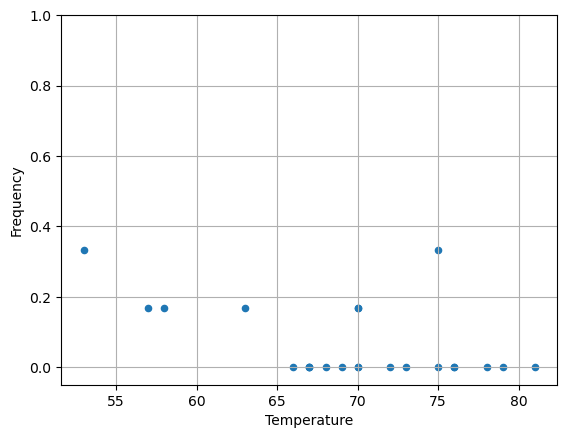

In [35]:
%matplotlib inline
pd.set_option('mode.chained_assignment',None) # this removes a useless warning from pandas
import matplotlib.pyplot as plt

data["Frequency"]=data.Malfunction/data.Count
data.plot(x="Temperature",y="Frequency",kind="scatter",ylim=[0,1])
plt.ylim(-0.05, 1)
plt.grid(True)
plt.show()

We have a high temperature variability but
the pressure is almost always 200, which should
simplify the analysis.

How does the frequency of failure vary with temperature?

## Estimation of the temperature influence

Suppose that each of the six O-rings is damaged with the same
probability and independently of the others and that this probability
depends only on the temperature. If $p(t)$ is this probability, the
number $D$ of malfunctioning O-rings during a flight at
temperature $t$ follows a binomial law with parameters $n=6$ and
$p=p(t)$. To link $p(t)$ to $t$, we will therefore perform a
logistic regression.

We model the probability of O-ring damage using a binomial logistic regression. The response is specified using the number of damaged O-rings and the number of undamaged O-rings for each flight. All flights are included in the model. This allows the estimated probability of damage to depend on temperature while accounting for the number of O-rings observed.

In [41]:
import statsmodels.api as sm

# Reload the complete dataset
data = pd.read_csv("shuttle.csv")
data["Frequency"] = data["Malfunction"] / data["Count"]

data["Success"] = data["Count"] - data["Malfunction"]
data["Intercept"] = 1

X = data[["Intercept", "Temperature"]]
y = data[["Malfunction", "Success"]]

logmodel = sm.GLM(
    y,
    X,
    family=sm.families.Binomial()
).fit()

print(logmodel.summary())

                     Generalized Linear Model Regression Results                      
Dep. Variable:     ['Malfunction', 'Success']   No. Observations:                   23
Model:                                    GLM   Df Residuals:                       21
Model Family:                        Binomial   Df Model:                            1
Link Function:                          Logit   Scale:                          1.0000
Method:                                  IRLS   Log-Likelihood:                -15.823
Date:                        Tue, 13 Oct 2026   Deviance:                       18.086
Time:                                13:40:39   Pearson chi2:                     30.0
No. Iterations:                             6   Pseudo R-squ. (CS):             0.2344
Covariance Type:                    nonrobust                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------


#### Interpretation

The estimated coefficient for Temperature is negative (-0.1156), suggesting that the probability of O-ring damage increases as temperature decreases. The p-value is 0.014, which is below the 5% significance level and provides evidence of an association between temperature and the probability of damage. However, the dataset is relatively small, so the results should be interpreted with caution.

### Estimation of the probability of O-ring malfunction

We use the fitted logistic regression model to estimate the probability of O-ring damage at different temperatures, including 31°F. The prediction at 31°F must be interpreted with caution if this temperature lies outside the observed range. In that case, the estimate relies on extrapolation and may be highly uncertain.

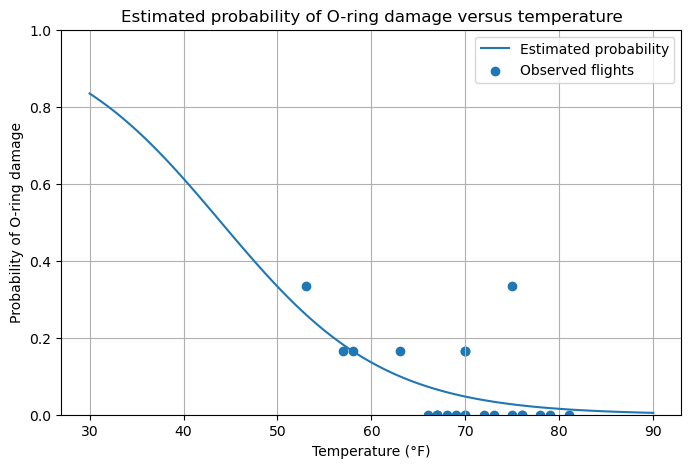

Estimated probability at 31°F: 0.8177744062821899


In [37]:
data_pred = pd.DataFrame({ "Temperature": np.linspace(30, 90, 121), "Intercept": 1})

data_pred["Frequency"] = logmodel.predict(data_pred[["Intercept", "Temperature"]])

plt.figure(figsize=(8, 5))
plt.plot(
    data_pred["Temperature"],
    data_pred["Frequency"],
    label="Estimated probability"
)
plt.scatter(
    data["Temperature"],
    data["Frequency"],
    label="Observed flights"
)
plt.xlabel("Temperature (°F)")
plt.ylabel("Probability of O-ring damage")
plt.title("Estimated probability of O-ring damage versus temperature")
plt.ylim(0, 1)
plt.grid(True)
plt.legend()
plt.show()

prediction_31 = logmodel.predict(
    pd.DataFrame({
        "Intercept": [1],
        "Temperature": [31]
    })
)

print("Estimated probability at 31°F:", float(prediction_31.iloc[0]))

### Interpretation
The fitted model estimates a probability of approximately 81.8% for O-ring damage at 31°F. However, the observed temperatures range from 53°F to 81°F. Since 31°F is outside this range, the prediction is an extrapolation and is therefore highly uncertain. It should not be treated as a precise estimate of the actual probability of damage.

In [29]:
# Estimate the probability of damage to one O-ring at 31°F
p_31 = float(prediction_31.iloc[0])

# Assuming independent primary and secondary O-rings
p_joint_failure = p_31 ** 2

# Assuming three independent launcher sections
p_any_failure = 1 - (1 - p_joint_failure) ** 3

print("Estimated probability for one O-ring at 31°F:", p_31)
print("Estimated probability of both O-rings failing:", p_joint_failure)
print("Estimated probability of at least one section failing:", p_any_failure)
print("Estimated overall risk (%):", 100 * p_any_failure)

Estimated probability for one O-ring at 31°F: 0.8177744062821899
Estimated probability of both O-rings failing: 0.6687549795701881
Estimated probability of at least one section failing: 0.9636547153205924
Estimated overall risk (%): 96.36547153205925


## Conclusion

This analysis suggests that lower temperatures are associated with a higher probability of O-ring damage in the Challenger shuttle data. The logistic regression model estimates a negative temperature coefficient (-0.1156), with a p-value of 0.014, providing statistical evidence of an association between temperature and O-ring damage.

At the expected launch temperature of 31°F, the model estimates a probability of approximately 81.8% that an individual O-ring will be damaged. However, the observed temperatures range from 53°F to 81°F, making this prediction an extrapolation with considerable uncertainty.

Under the simplifying independence assumptions used in the calculations, the estimated probability of at least one of the three sections experiencing the specified failure event is approximately 96.4%. This figure should be interpreted cautiously, as it depends on both the extrapolation to 31°F and the assumptions about the independence of failures.

Overall, the results highlight a potential increase in O-ring damage risk at lower temperatures. Given the small dataset and the uncertainty of predictions outside the observed temperature range, these estimates should not be considered precise measures of the actual launch risk.

### GOOD / BAD 

The document is good because it uses a statistical model and shows that lower temperatures may increase O-ring damage. However, the prediction at 31°F is uncertain because the data only covers temperatures from 53°F to 81°F. The 96.4% risk estimate also depends on assumptions that may not be true. Therefore, the results should be interpreted with caution.